<a href="https://colab.research.google.com/github/sherabbas173/Sher/blob/main/mushroom_classification_cnn_rnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, SimpleRNN

df = pd.read_csv("mushrooms.csv")
print(df.shape)
print(df.head())
df.info()
print(df['class'].value_counts())

(8124, 23)
  class cap-shape cap-surface cap-color bruises odor gill-attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill-spacing gill-size gill-color  ... stalk-surface-below-ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk-color-above-ring stalk-color-below-ring veil-type veil-color  \
0                      w                      w         p          w 

In [2]:
df_enc = df.copy()
for col in df_enc.columns:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col])

X = df_enc.drop('class', axis=1).values.astype('float32')
y = df_enc['class'].values

# 70% train, 30% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

# CNN aur RNN ke liye reshape: (samples, timesteps, features)
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test  = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)
print(X_train.shape, X_test.shape)

(5686, 22, 1) (2438, 22, 1)


In [3]:
cnn = Sequential([
    Conv1D(32, 3, activation='relu', input_shape=(X_train.shape[1], 1)),
    MaxPooling1D(2),
    Conv1D(64, 3, activation='relu'),
    MaxPooling1D(2),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.summary()
cnn_hist = cnn.fit(X_train, y_train, batch_size=30, epochs=10,
                   validation_data=(X_test, y_test))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 20, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 10, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 8, 64)          │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,849 (89.25 KB)

 Trainable params: 22,849 (89.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8366 - loss: 0.3689 - val_accuracy: 0.9212 - val_loss: 0.1925
Epoch 2/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9376 - loss: 0.1519 - val_accuracy: 0.9639 - val_loss: 0.0969
Epoch 3/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9671 - loss: 0.0833 - val_accuracy: 0.9651 - val_loss: 0.0818
Epoch 4/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9870 - loss: 0.0453 - val_accuracy: 0.9938 - val_loss: 0.0230
Epoch 5/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9896 - loss: 0.0352 - val_accuracy: 0.9947 - val_loss: 0.0188
Epoch 6/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9909 - loss: 0.0271 - val_accuracy: 0.9975 - val_loss: 0.0134
Epoch 7/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9951 - loss: 0.0165 - val_accuracy: 0.9984 - val_loss: 0.0111
Epoch 8/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9982 - loss: 0.0089 - val_accuracy: 0.

In [4]:
rnn = Sequential([
    SimpleRNN(64, input_shape=(X_train.shape[1], 1)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
rnn.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])
rnn.summary()
rnn_hist = rnn.fit(X_train, y_train, batch_size=40, epochs=20,
                   validation_data=(X_test, y_test))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.8888 - loss: 0.2896 - val_accuracy: 0.9422 - val_loss: 0.1797
Epoch 2/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9689 - loss: 0.0893 - val_accuracy: 0.9930 - val_loss: 0.0322
Epoch 3/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9877 - loss: 0.0377 - val_accuracy: 0.9651 - val_loss: 0.0675
Epoch 4/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9923 - loss: 0.0231 - val_accuracy: 0.9971 - val_loss: 0.0075
Epoch 5/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9938 - loss: 0.0153 - val_accuracy: 0.9938 - val_loss: 0.0107
Epoch 6/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9960 - loss: 0.0132 - val_accuracy: 0.9975 - val_loss: 0.0068
Epoch 7/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9963 - loss: 0.0117 - val_accuracy: 0.9992 - val_loss: 0.0035
Epoch 8/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9967 - loss: 0.0093 - val_accuracy: 0

In [5]:
cnn_pred = (cnn.predict(X_test) > 0.5).astype(int).ravel()
rnn_pred = (rnn.predict(X_test) > 0.5).astype(int).ravel()
print("CNN predictions:", cnn_pred[:20])
print("RNN predictions:", rnn_pred[:20])
print("Actual labels  :", y_test[:20])

77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
CNN predictions: [1 1 0 1 0 1 1 1 1 0 1 1 0 0 1 1 0 1 0 0]
RNN predictions: [1 1 0 1 0 1 1 1 1 0 1 1 0 0 1 1 0 1 0 0]
Actual labels  : [1 1 0 1 0 1 1 1 1 0 1 1 0 0 1 1 0 1 0 0]


CNN Test Accuracy: 1.0000
RNN Test Accuracy: 0.9992
Best model: CNN


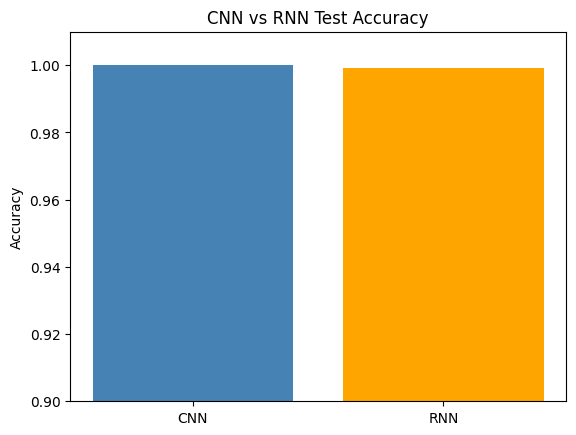

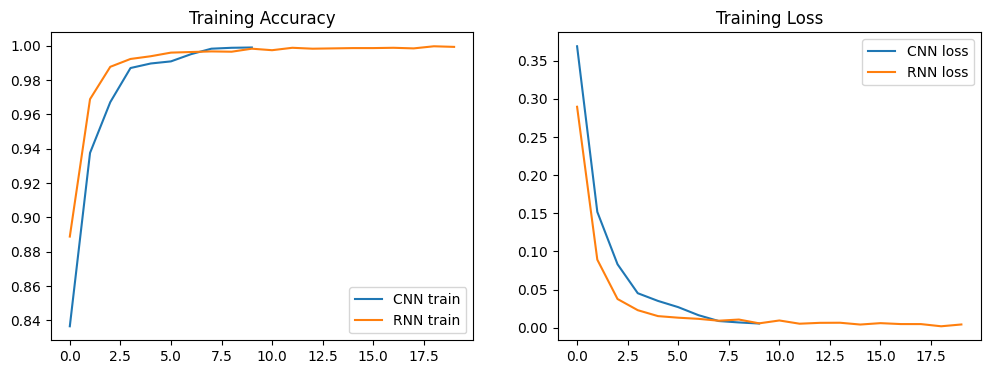

In [6]:
cnn_acc = accuracy_score(y_test, cnn_pred)
rnn_acc = accuracy_score(y_test, rnn_pred)
print(f"CNN Test Accuracy: {cnn_acc:.4f}")
print(f"RNN Test Accuracy: {rnn_acc:.4f}")
print("Best model:", "CNN" if cnn_acc > rnn_acc else "RNN" if rnn_acc > cnn_acc else "Both equal")

# Bar chart
plt.bar(['CNN','RNN'], [cnn_acc, rnn_acc], color=['steelblue','orange'])
plt.ylim(0.9, 1.01); plt.ylabel('Accuracy'); plt.title('CNN vs RNN Test Accuracy')
plt.show()

# Training curves
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(cnn_hist.history['accuracy'], label='CNN train')
ax[0].plot(rnn_hist.history['accuracy'], label='RNN train')
ax[0].set_title('Training Accuracy'); ax[0].legend()
ax[1].plot(cnn_hist.history['loss'], label='CNN loss')
ax[1].plot(rnn_hist.history['loss'], label='RNN loss')
ax[1].set_title('Training Loss'); ax[1].legend()
plt.show()

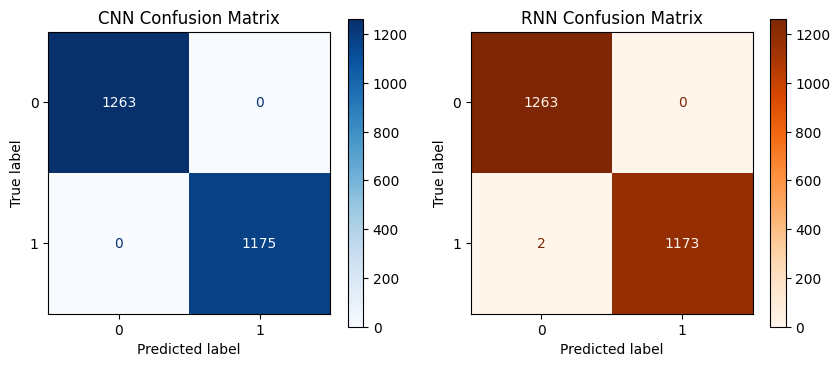

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))
ConfusionMatrixDisplay(confusion_matrix(y_test, cnn_pred)).plot(ax=ax[0], cmap='Blues')
ax[0].set_title('CNN Confusion Matrix')
ConfusionMatrixDisplay(confusion_matrix(y_test, rnn_pred)).plot(ax=ax[1], cmap='Oranges')
ax[1].set_title('RNN Confusion Matrix')
plt.show()

In [8]:
print("CNN Report\n", classification_report(y_test, cnn_pred, target_names=['edible','poisonous']))
print("RNN Report\n", classification_report(y_test, rnn_pred, target_names=['edible','poisonous']))

CNN Report
               precision    recall  f1-score   support

      edible       1.00      1.00      1.00      1263
   poisonous       1.00      1.00      1.00      1175

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438

RNN Report
               precision    recall  f1-score   support

      edible       1.00      1.00      1.00      1263
   poisonous       1.00      1.00      1.00      1175

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438



In [9]:
print("RNN Report\n", classification_report(y_test, rnn_pred, target_names=['edible','poisonous'], digits=4))

RNN Report
               precision    recall  f1-score   support

      edible     0.9984    1.0000    0.9992      1263
   poisonous     1.0000    0.9983    0.9991      1175

    accuracy                         0.9992      2438
   macro avg     0.9992    0.9991    0.9992      2438
weighted avg     0.9992    0.9992    0.9992      2438



In [10]:
!pip install transformers

import json
from transformers import AutoTokenizer
with open("exercise_text.json", "r", encoding="utf-8") as f:
    data = json.load(f)
text = data["text"]
print("Original Text:\n", text)
print("\nTotal characters:", len(text))

Original Text:
 In this exercise, you are required to Apply and evaluate CNN, ANN, and RNN models Compare their performance and identify the model that achieves the highest accuracy for image classification using the **Iris Flowers dataset**. You will load and preprocess image data, design a multi-layer CNN architecture using TensorFlow/Keras, and train the model to recognize different object categories. After training, you will evaluate the model's performance on unseen test data and visualize the training loss across epochs. The objective of this exercise is to provide hands-on experience with **Deep Learning and Computer Vision**, enabling you to understand the complete workflow of an image classification project. Also solve the Large Language Models (LLMs) Architecture & Work. And Using LLMs with LangChain, passing prompts programmatically.

Total characters: 840


In [11]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

tokens = tokenizer.tokenize(text)
print("Total tokens:", len(tokens))
print("First 30 tokens:", tokens[:30])

ids = tokenizer.convert_tokens_to_ids(tokens)
print("First 30 Token IDs:", ids[:30])

encoded = tokenizer(text)
print("\nInput IDs:", encoded["input_ids"][:30])
print("Attention Mask:", encoded["attention_mask"][:30])

print("\nDecoded:", tokenizer.decode(encoded["input_ids"]))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Total tokens: 173
First 30 tokens: ['in', 'this', 'exercise', ',', 'you', 'are', 'required', 'to', 'apply', 'and', 'evaluate', 'cnn', ',', 'ann', ',', 'and', 'rn', '##n', 'models', 'compare', 'their', 'performance', 'and', 'identify', 'the', 'model', 'that', 'achieve', '##s', 'the']
First 30 Token IDs: [1999, 2023, 6912, 1010, 2017, 2024, 3223, 2000, 6611, 1998, 16157, 13229, 1010, 5754, 1010, 1998, 29300, 2078, 4275, 12826, 2037, 2836, 1998, 6709, 1996, 2944, 2008, 6162, 2015, 1996]

Input IDs: [101, 1999, 2023, 6912, 1010, 2017, 2024, 3223, 2000, 6611, 1998, 16157, 13229, 1010, 5754, 1010, 1998, 29300, 2078, 4275, 12826, 2037, 2836, 1998, 6709, 1996, 2944, 2008, 6162, 2015]
Attention Mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Decoded: [CLS] in this exercise, you are required to apply and evaluate cnn, ann, and rnn models compare their performance and identify the model that achieves the highest accuracy for image classification u

In [12]:
import textwrap
print(textwrap.fill(tokenizer.decode(encoded["input_ids"]), width=100))

[CLS] in this exercise, you are required to apply and evaluate cnn, ann, and rnn models compare
their performance and identify the model that achieves the highest accuracy for image classification
using the * * iris flowers dataset * *. you will load and preprocess image data, design a multi -
layer cnn architecture using tensorflow / keras, and train the model to recognize different object
categories. after training, you will evaluate the model ' s performance on unseen test data and
visualize the training loss across epochs. the objective of this exercise is to provide hands - on
experience with * * deep learning and computer vision * *, enabling you to understand the complete
workflow of an image classification project. also solve the large language models ( llms )
architecture & work. and using llms with langchain, passing prompts programmatically. [SEP]
